In [1]:
import cantera as ct
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# provide discrete enthalpy and entropy values calculated with DFT
# array of CO* coverage
dft_covs = [0., 0.11, 0.22, 0.33, 0.44, 0.56, 0.67, 0.78, 0.89, 1.0]
# array of nondimensionalized DFT-derived CO* enthalpy values
dft_hrts = [-112.8 , -112.8 , -108.78, -105.76, -106.11, -102.51,  -96.83,
            -85.03,  -78.76,  -72.19]
# array of nondimensionalized DFT-derived CO* entropy values
dft_srs = [2.46, 2.46, 3.79, 3.28, 3.14, 2.41, 2.19, 1.63, 1.6 , 1.12]

# create a dictionary to store coverage-dependent enthalpy and entropy
# from the four dependency models. key is the model name and value is
# a dictionary of yaml's phase name, enthalpy, and entropy
models_dict = {'linear': {'phase_name': 'covdep_lin'},
               'piecewise-linear': {'phase_name': 'covdep_pwlin'},
               'polynomial': {'phase_name': 'covdep_poly'},
               'interpolative': {'phase_name': 'covdep_int'}}

# create an array of CO* coverages from 0 (no CO*) to 1 (full mono-layer)
CO_covs = np.linspace(0, 1.0, 101)
# remember CO* species index
i_CO = 1

# get coverage-dependent enthalpy and entropy for all four models
for model in models_dict:
    # dependency parameters are provided in covdepsurf.yaml
    # import a phase from covdepsurf.yaml and set temperature and pressure
    phase = ct.Interface('example_data/covdepsurf.yaml',
                         models_dict[model]['phase_name'])
    phase.TP = 300, ct.one_atm
    # under the current model, create empty lists to store enthalpy and
    # entropy
    models_dict[model]['hrt'] = []
    models_dict[model]['sr'] = []
    # sweep through the array of CO* coverages and store enthalpy and entropy
    for CO_cov in CO_covs:
        # set coverages in order of [Pt_cov, CO_cov]
        phase.coverages = [1 - CO_cov, CO_cov]
        # get and store enthalpy and entropy values to the corresponding list
        models_dict[model]['hrt'].append(phase.standard_enthalpies_RT[i_CO])
        models_dict[model]['sr'].append(phase.standard_entropies_R[i_CO])

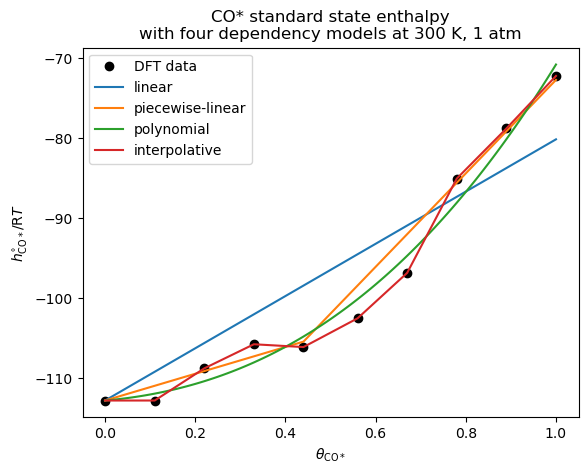

In [3]:
fig, ax = plt.subplots()
ax.plot(dft_covs, dft_hrts, marker='o', color='k', linewidth=0, label='DFT data')
for model in models_dict:
    ax.plot(CO_covs, models_dict[model]['hrt'], label=model)
ax.set(xlabel=r'$\theta_\mathrm{CO*}$')
ax.set(ylabel=r'$h^{\circ}_\mathrm{CO*}/\mathrm{R}T$')
ax.legend(loc='best')
ax.set_title('CO* standard state enthalpy\nwith four dependency models at 300 K, 1 atm')
plt.show()

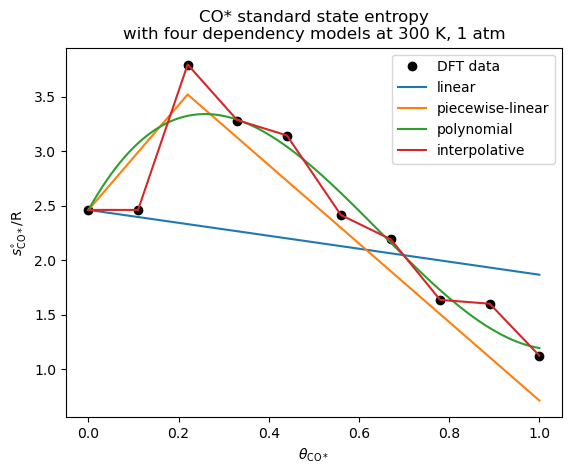

In [4]:
fig, ax = plt.subplots()
ax.plot(dft_covs, dft_srs, marker='o', color='k', linewidth=0, label='DFT data')
for model in models_dict:
    ax.plot(CO_covs, models_dict[model]['sr'], label=model)
ax.set(xlabel=r'$\theta_\mathrm{CO*}$')
ax.set(ylabel=r'$s^{\circ}_\mathrm{CO*}/\mathrm{R}$')
ax.legend(loc='best')
ax.set_title('CO* standard state entropy\nwith four dependency models at 300 K, 1 atm')
plt.show()

In [6]:
# import a phase with both types of lateral interactions
phase = ct.Interface('example_data/covdepsurf.yaml', 'covdep_cross')
phase.TP = 300, ct.one_atm

# create an array of coverages
covs = np.linspace(0, 1.0, 101)
# create N by N matrix to store CO* enthalpy values
CO_hrts = np.zeros(shape=(len(covs),len(covs)))

# iterate through the coverage array and fill in CO*enthalpy values
for i, CO_cov in enumerate(covs):
    for j in range(len(covs)-i):
        O_cov = covs[j]
        # set coverages in order of [Pt_cov, CO_cov, O_cov]
        phase.coverages = [1. - CO_cov - O_cov, CO_cov, O_cov]
        CO_hrts[i,j] = phase.standard_enthalpies_RT[i_CO]

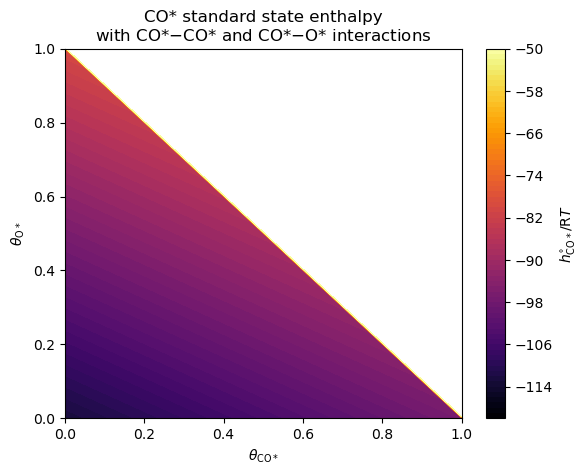

In [7]:
fig, ax = plt.subplots()
cntr = ax.contourf(covs, covs, CO_hrts,
                   levels=np.linspace(-120, -50, 71),
                   cmap='inferno')

ax.set(xlabel=r'$\theta_\mathrm{CO*}$', ylabel=r'$\theta_\mathrm{O*}$')
cbar = fig.colorbar(cntr)
cbar.ax.set_ylabel(r'$h^{\circ}_\mathrm{CO*}/\mathrm{R}T$')
ax.set_title('CO* standard state enthalpy\nwith CO*$-$CO* and CO*$-$O* interactions')
plt.show()